# What the orphan co-folding screen says, at 4,913 folds

The screen folded candidate partners against 75 orphan GPCRs with AlphaFold3 and
omicMSAs. It is now closed: 4,913 of 5,000 candidates were folded and the remaining 87
were dropped.

This notebook asks three questions, in order of how much rests on them:

1. **Does the headline survive the screen growing from 3,017 to 4,913 folds?** The folds
   that landed late are not a random sample — the queue was size-ordered, so they are the
   large complexes, and they cover a size range the earlier snapshot never reached.
2. **Is the metabolite result a result about binding, or about ipTM?** Three independent
   2026 benchmarks report that for a small partner ipTM is the weakest available
   confidence term and the partner chain's own pLDDT is the one that discriminates. The
   scorer now emits both, so this costs no re-folding.
3. **What survives as a shortlist**, once promiscuity and geometry are applied with
   denominators that do not flatter an unfinished screen.

## 1. What is actually in hand

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats

ROOT = Path("/data/yzy21/yy/space_agent/structural_modelling")
sys.path.insert(0, str(ROOT / "scripts"))
pd.set_option("display.width", 185)
pd.set_option("display.max_columns", 40)

RED, BLUE, GREY, INK = "#B2182B", "#2166AC", "#9A9AA2", "#1A1A1F"
PURPLE = "#6A51A3"
KIND_COLOUR = {"protein": BLUE, "metabolite": RED}
mpl.rcParams.update({"figure.dpi": 120, "font.size": 8, "axes.labelsize": 8,
                     "axes.titlesize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
                     "legend.fontsize": 7, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})

In [2]:
# the scorer writes a coverage record beside every result: read it before the numbers,
# so the fraction of the screen behind them is on the page first
SCORES = ROOT / "results" / "orphan_scores.csv"
cov = json.loads(SCORES.with_suffix(".coverage.json").read_text())
cov

{'written_utc': '2026-11-23T12:48:18Z',
 'code_fingerprint': '56c204c4f843',
 'manifest_folds': 5000,
 'scored': 4913,
 'ready_on_disk': 4913,
 'writing_now': 0,
 'queued_not_started': 87,
 'stalled_no_runner': 0,
 'stage_live': None,
 'never_started': 0,
 'unexpected_on_disk': 0,
 'complete': False,
 'allow_shrink': False,
 'scored_by_kind': {'protein': 4767, 'metabolite': 146},
 'reused_rows': 0,
 'newly_scored': 4913}

In [3]:
man = pd.read_csv(ROOT / "work" / "orphan_manifest.csv")
d = pd.read_csv(SCORES)
dropped = pd.read_csv(ROOT / "results" / "orphan_dropped.csv")

# a row with a note has no fold behind it; keep the two apart rather than letting a
# failed parse sit in the table looking like a measured zero
ok = d[d.note.fillna("").eq("") & d.iptm.notna()].copy()
print(f"manifest            {len(man):,} candidates")
print(f"scored rows         {len(d):,}")
print(f"usable folds        {len(ok):,}")
print(f"dropped on purpose  {len(dropped):,}")
print(f"coverage            {len(ok)/len(man):.1%} of the manifest")
print()
print(ok.kind.value_counts().to_string())

manifest            5,000 candidates
scored rows         4,913
usable folds        4,913
dropped on purpose  87
coverage            98.3% of the manifest

kind
protein       4767
metabolite     146


/tmp/ipykernel_2313243/3487669696.py:7: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  ok = d[d.note.fillna("").eq("") & d.iptm.notna()].copy()


### What the drop removed

Not a random 87. One arm of the design is gone entirely, which has to be said before any
comparison between arms.

In [4]:
tab = pd.DataFrame({
    "dropped": dropped.msa_source.value_counts(),
    "in_manifest": man.msa_source.value_counts()}).fillna(0).astype(int)
tab["share_of_arm_lost"] = (tab.dropped / tab.in_manifest).map("{:.1%}".format)
print(tab.to_string())
print()
print("reasons:")
print(dropped.drop_reason.value_counts().to_string())

                         dropped  in_manifest share_of_arm_lost
msa_source                                                     
omic_paired                    2         4769              0.0%
omic_receptor_only             0          146              0.0%
partner_single_sequence       85           85            100.0%

reasons:
drop_reason
input had no embedded MSA (since repaired, never re-folded)    85
CUDA out of memory                                              2


In [5]:
# the dropped folds are much larger, which invites the wrong conclusion. Test it:
# if a GPU size ceiling were the cause, large candidates generally would be missing
folded = set(ok.pair)
big = man[man["size"] >= dropped["size"].min()]
print(f"dropped median size  {dropped['size'].median():,.0f} tokens")
print(f"folded  median size  {man[man.job.isin(folded)]['size'].median():,.0f} tokens")
print(f"  ratio {dropped['size'].median()/man[man.job.isin(folded)]['size'].median():.1f}x")
print()
print(f"of the {len(big):,} candidates at or above the smallest dropped size, "
      f"{int(big.job.isin(folded).sum()):,} folded ({big.job.isin(folded).mean():.0%})")
print("-> size is not what decided it; the partners lacking an omicMSA are simply large "
      "proteins (neurexins, teneurins)")

dropped median size  3,171 tokens
folded  median size  820 tokens
  ratio 3.9x

of the 4,471 candidates at or above the smallest dropped size, 4,384 folded (98%)
-> size is not what decided it; the partners lacking an omicMSA are simply large proteins (neurexins, teneurins)


## 2. Does the headline move between 3,017 and 4,913 folds?

The comparison is only meaningful arm by arm. The metabolite arm was already complete at
the earlier snapshot, so it cannot move and must stand on other grounds. The protein arm
grew by 1.6x, across a size range the earlier snapshot barely sampled.

In [6]:
before = pd.read_csv(ROOT / "results" / "orphan_scores_at3017_2026-11-20.csv")
before = before[before.note.fillna("").eq("") & before.iptm.notna()]

def headline(df, label):
    g = df.groupby("kind").agg(
        n=("iptm", "size"),
        median_iptm=("iptm", "median"),
        frac_conf=("iptm", lambda s: (s >= 0.5).mean()),
        median_bsa=("bsa", "median"),
        median_ncontact=("n_contact", "median"))
    g.insert(0, "snapshot", label)
    return g.round(3)

cmp = pd.concat([headline(before, "3,017 folds"), headline(ok, "4,913 folds")])
print(cmp.sort_index().to_string())

               snapshot     n  median_iptm  frac_conf  median_bsa  median_ncontact
kind                                                                              
metabolite  3,017 folds   140        0.850      0.986     409.426            113.0
metabolite  4,913 folds   146        0.845      0.973     406.409            106.5
protein     3,017 folds  2859        0.210      0.021    2597.667            466.0
protein     4,913 folds  4767        0.240      0.032    3010.826            551.0


In [7]:
# the protein arm over the full size range, now that it exists
p = ok[ok.kind.eq("protein")].merge(man[["job", "size"]], left_on="pair", right_on="job")
p["decile"] = pd.qcut(p["size"], 10, duplicates="drop")
t = p.groupby("decile", observed=True).agg(
    n=("iptm", "size"), median_iptm=("iptm", "median"),
    frac_conf=("iptm", lambda s: (s >= 0.5).mean()),
    median_bsa=("bsa", "median"), median_plddt_B=("plddt_B", "median"))
print(t.round(3).to_string())
rho, pv = stats.spearmanr(p["size"], p.iptm, nan_policy="omit")
print(f"\nipTM vs complex size, protein arm: rho = {rho:+.3f}, p = {pv:.2g}, n = {len(p):,}")

                    n  median_iptm  frac_conf  median_bsa  median_plddt_B
decile                                                                   
(365.999, 518.0]  481         0.21      0.027    2395.798          58.786
(518.0, 601.0]    478         0.20      0.023    2440.676          60.416
(601.0, 686.0]    478         0.21      0.031    2569.578          63.315
(686.0, 737.0]    471         0.20      0.013    2507.671          65.742
(737.0, 831.0]    481         0.20      0.008    2755.688          63.558
(831.0, 937.0]    478         0.23      0.029    3008.734          65.037
(937.0, 1150.4]   470         0.24      0.023    3370.515          64.506
(1150.4, 1371.0]  480         0.26      0.042    3773.174          68.220
(1371.0, 1718.4]  473         0.28      0.051    3840.172          68.138
(1718.4, 3952.0]  477         0.30      0.069    5598.339          65.611

ipTM vs complex size, protein arm: rho = +0.362, p = 1.5e-147, n = 4,767


In [8]:
# and the same question asked as "would the earlier snapshot have predicted this?"
early = p[p.pair.isin(before.pair)]
late  = p[~p.pair.isin(before.pair)]
for name, sub in [("folds in the earlier snapshot", early), ("folds added since", late)]:
    print(f"{name:32s} n={len(sub):5,}  size {sub['size'].median():5.0f}  "
          f"median ipTM {sub.iptm.median():.3f}  confident {(sub.iptm>=0.5).mean():.3%}")
ct = pd.crosstab(p.pair.isin(before.pair).map({True: "earlier", False: "added"}),
                 p.iptm.ge(0.5).map({True: "confident", False: "not"}))
print()
print(ct.to_string())
chi = stats.fisher_exact(ct.values)
print(f"\nFisher exact on confident-rate between the two batches: p = {chi[1]:.3g}, "
      f"odds ratio {chi[0]:.2f}")

folds in the earlier snapshot    n=2,859  size   686  median ipTM 0.210  confident 2.099%
folds added since                n=1,908  size  1371  median ipTM 0.270  confident 4.769%

iptm     confident   not
pair                    
added           91  1817
earlier         60  2799

Fisher exact on confident-rate between the two batches: p = 4.52e-07, odds ratio 2.34


## 3. The metabolite result: binding, or ipTM?

ipTM calls essentially every metabolite fold confident. Whether that is a statement about
binding depends on whether the confidence means what it says, and the published position
is that for a small partner it does not: Kim *et al.* (eLife 2026) found AF3
ligand-pLDDT their best metric, Ferguson *et al.* (Mol Cell 2026) found peptide pLDDT beat
both ipTM and pocket PAE, and Shamir *et al.* (JACS 2026) rejected protein-only metrics
outright. `plddt_B` is the partner chain's own confidence — the ligand itself for a
metabolite fold.

In [9]:
cols = ["iptm", "iptm_AB", "pae_min_AB", "plddt_A", "plddt_B", "iface_plddt",
        "iface_plddt_A", "iface_plddt_B", "mean_plddt", "bsa", "n_contact",
        "n_res_iface", "min_sep", "fraction_disordered"]
cols = [c for c in cols if c in ok.columns]
print(ok.groupby("kind")[cols].median().round(2).T.to_string())

kind                 metabolite  protein
iptm                       0.84     0.24
iptm_AB                    0.84     0.24
pae_min_AB                 3.23    15.58
plddt_A                   69.91    66.14
plddt_B                   64.49    64.39
iface_plddt               81.86    60.42
iface_plddt_A             84.97    62.30
iface_plddt_B             64.57    58.09
mean_plddt                69.89    64.96
bsa                      406.41  3010.83
n_contact                106.50   551.00
n_res_iface               12.00    75.00
min_sep                    2.47     2.12
fraction_disordered        0.24     0.24


In [10]:
# the fraction of each arm clearing a bar, metric by metric. A metric on which the two
# arms separate as strongly as ipTM does is a metric that agrees with ipTM; one on which
# they do not is a metric that disagrees, and the literature says to prefer the latter.
bars = {
    "ipTM >= 0.5":                    ok.iptm.ge(0.5),
    "ipTM >= 0.8":                    ok.iptm.ge(0.8),
    "partner pLDDT >= 70":            ok.plddt_B.ge(70),
    "partner pLDDT >= 50":            ok.plddt_B.ge(50),
    "partner interface pLDDT >= 70":  ok.iface_plddt_B.ge(70),
    "interface PAE <= 5 A":           ok.pae_min_AB.le(5),
    "BSA >= 300 A^2":                 ok.bsa.ge(300),
    "no clash (min_sep >= 1.5 A)":    ok.min_sep.ge(1.5),
    "ipTM >= 0.5 AND partner pLDDT >= 70": ok.iptm.ge(0.5) & ok.plddt_B.ge(70),
}
rows = []
for name, mask in bars.items():
    r = {"criterion": name}
    for k, g in ok.groupby("kind"):
        r[k] = round(float(mask.reindex(g.index).mean()), 3)
    r["ratio_met_over_prot"] = (round(r["metabolite"] / r["protein"], 1)
                                if r.get("protein") else np.nan)
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

                          criterion  metabolite  protein  ratio_met_over_prot
                        ipTM >= 0.5       0.973    0.032                 30.4
                        ipTM >= 0.8       0.801    0.000                  NaN
                partner pLDDT >= 70       0.308    0.233                  1.3
                partner pLDDT >= 50       0.959    0.866                  1.1
      partner interface pLDDT >= 70       0.308    0.137                  2.2
               interface PAE <= 5 A       0.925    0.027                 34.3
                     BSA >= 300 A^2       0.705    0.998                  0.7
        no clash (min_sep >= 1.5 A)       0.877    0.888                  1.0
ipTM >= 0.5 AND partner pLDDT >= 70       0.308    0.013                 23.7


A caution that limits what the table can settle: for a metabolite fold chain B is a small
molecule of a few dozen atoms, and for a protein fold it is a whole protein. Their pLDDT
distributions are not on the same scale, so the between-arm comparison is suggestive and
not decisive. The comparison that **is** clean is within the metabolite arm: among folds
ipTM calls confident, does the ligand's own confidence agree?

In [11]:
met = ok[ok.kind.eq("metabolite")]
conf = met[met.iptm.ge(0.5)]
print(f"metabolite folds: {len(met)}, of which ipTM-confident: {len(conf)} "
      f"({len(conf)/len(met):.1%})")
print()
for name, mask in [("also partner pLDDT >= 70", conf.plddt_B.ge(70)),
                   ("also partner pLDDT >= 50", conf.plddt_B.ge(50)),
                   ("also interface PAE <= 5 A", conf.pae_min_AB.le(5)),
                   ("also BSA >= 300 A^2", conf.bsa.ge(300)),
                   ("also no clash", conf.min_sep.ge(1.5))]:
    print(f"  of the ipTM-confident, {name:28s} {int(mask.sum()):4d}  ({mask.mean():.1%})")
print()
r = stats.spearmanr(met.iptm, met.plddt_B, nan_policy="omit")
print(f"within the metabolite arm, ipTM vs ligand pLDDT: rho = {r.statistic:+.3f}, "
      f"p = {r.pvalue:.2g}")
r2 = stats.spearmanr(ok[ok.kind.eq('protein')].iptm,
                     ok[ok.kind.eq('protein')].plddt_B, nan_policy="omit")
print(f"within the protein arm,    ipTM vs partner pLDDT: rho = {r2.statistic:+.3f}, "
      f"p = {r2.pvalue:.2g}")

metabolite folds: 146, of which ipTM-confident: 142 (97.3%)

  of the ipTM-confident, also partner pLDDT >= 70       45  (31.7%)
  of the ipTM-confident, also partner pLDDT >= 50      140  (98.6%)
  of the ipTM-confident, also interface PAE <= 5 A     135  (95.1%)
  of the ipTM-confident, also BSA >= 300 A^2           103  (72.5%)
  of the ipTM-confident, also no clash                 126  (88.7%)

within the metabolite arm, ipTM vs ligand pLDDT: rho = +0.794, p = 5.7e-33
within the protein arm,    ipTM vs partner pLDDT: rho = +0.137, p = 1.9e-21


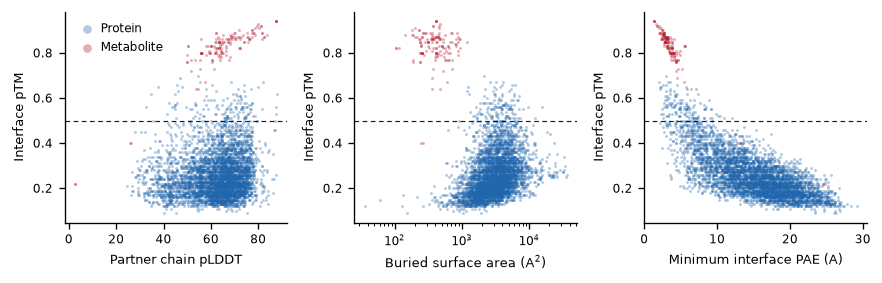

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.4))
for ax, (x, lab) in zip(axes, [("plddt_B", "Partner chain pLDDT"),
                               ("bsa", "Buried surface area (A$^2$)"),
                               ("pae_min_AB", "Minimum interface PAE (A)")]):
    for kind in ("protein", "metabolite"):
        s = ok[ok.kind.eq(kind)]
        ax.scatter(s[x], s.iptm, s=3, c=KIND_COLOUR[kind], alpha=0.35, linewidths=0,
                   label=kind.capitalize())
    ax.axhline(0.5, color=INK, lw=0.7, ls=(0, (4, 3)))
    if x == "bsa":
        ax.set_xscale("log")
    ax.set_xlabel(lab); ax.set_ylabel("Interface pTM")
axes[0].legend(frameon=False, markerscale=3, handletextpad=0.2)
fig.tight_layout(); plt.show()

## 4. Promiscuity: a partner confident against everything is a statement about the partner

The denominator has to be the receptors a partner was actually folded against, and the
count of those has to be reported, because a partner confident at 3 of 3 is a much weaker
claim than one confident at 70 of 70.

In [13]:
confident = ok[(ok.iptm >= 0.5) & (ok.min_sep >= 1.5)]
g = ok.groupby(["partner", "kind"]).receptor.nunique().rename("tested").reset_index()
g["confident"] = g.partner.map(confident.groupby("partner").receptor.nunique()).fillna(0).astype(int)
g["designed"] = g.partner.map(man.groupby("partner").receptor.nunique()).fillna(0).astype(int)
g["hit_rate"] = g.confident / g.tested
g["coverage"] = (g.tested / g.designed).round(3)
print(f"partners: {len(g)}   with their full receptor set folded: {int((g.coverage>=1).sum())}")
print()
full = g[(g.coverage >= 1) & (g.tested >= 10)]
print(f"restricted to partners folded against >=10 receptors with full coverage (n={len(full)}):")
for k in ("metabolite", "protein"):
    s = full[full.kind.eq(k)]
    if len(s):
        print(f"  {k:11s} {int((s.hit_rate==1).sum()):3d} of {len(s):4d} are confident "
              f"against EVERY receptor  ({(s.hit_rate==1).mean():.1%})")

partners: 1035   with their full receptor set folded: 1033

restricted to partners folded against >=10 receptors with full coverage (n=113):
  metabolite    1 of    4 are confident against EVERY receptor  (25.0%)
  protein       0 of  109 are confident against EVERY receptor  (0.0%)


In [14]:
print("the most promiscuous partners (full coverage, >=10 receptors):")
print(full.sort_values(["hit_rate", "tested"], ascending=False)
      .head(20)[["partner", "kind", "tested", "confident", "hit_rate"]]
      .round(3).to_string(index=False))

the most promiscuous partners (full coverage, >=10 receptors):
 partner       kind  tested  confident  hit_rate
  SLC1A7 metabolite      10         10     1.000
     DBH metabolite      11         10     0.909
  SLC1A2 metabolite      12         10     0.833
   PTGDS metabolite      11          8     0.727
    PPIA    protein      11          4     0.364
   ITGAM    protein      10          2     0.200
SIGLEC10    protein      10          2     0.200
    GHRL    protein      11          2     0.182
   IL21R    protein      11          2     0.182
   PTPRC    protein      12          2     0.167
   CD226    protein      13          2     0.154
    BMP6    protein      14          2     0.143
    CFC1    protein      14          2     0.143
CATSPER2    protein      10          1     0.100
  GRIN2A    protein      10          1     0.100
  HAVCR2    protein      10          1     0.100
 IL12RB1    protein      10          1     0.100
   ITGB4    protein      10          1     0.100
   ITG

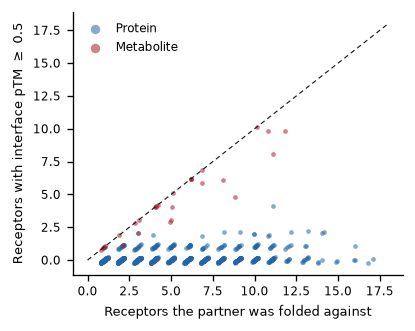

In [15]:
fig, ax = plt.subplots(figsize=(3.5, 2.8))
for kind in ("protein", "metabolite"):
    s = g[g.kind.eq(kind)]
    j = np.random.default_rng(0).uniform(-0.2, 0.2, len(s))
    ax.scatter(s.tested + j, s.confident + j, s=8, c=KIND_COLOUR[kind], alpha=0.55,
               linewidths=0, label=kind.capitalize())
lim = g.tested.max() + 1
ax.plot([0, lim], [0, lim], color=INK, lw=0.7, ls=(0, (4, 3)))
ax.set_xlabel("Receptors the partner was folded against")
ax.set_ylabel("Receptors with interface pTM $\\geq$ 0.5")
ax.legend(frameon=False, markerscale=2, loc="upper left")
fig.tight_layout(); plt.show()

## 5. Geometry: how many confident calls are physically possible

In [16]:
c = ok[ok.iptm.ge(0.5)]
print(f"ipTM-confident folds: {len(c):,} of {len(ok):,}")
for name, mask in [("clash, min_sep < 1.5 A", c.min_sep.lt(1.5)),
                   ("AF3's own has_clash flag", c.has_clash.astype(float).gt(0)),
                   ("interface smaller than 300 A^2", c.bsa.lt(300)),
                   ("fewer than 20 contacts", c.n_contact.lt(20)),
                   ("partner pLDDT below 50", c.plddt_B.lt(50)),
                   ("mostly disordered (>0.5)", c.fraction_disordered.gt(0.5))]:
    print(f"  {name:34s} {int(mask.sum()):5d}  ({mask.mean():6.1%})")
print()
print("by arm:")
print(c.groupby("kind").agg(n=("iptm","size"),
                            clash=("min_sep", lambda s: (s<1.5).mean()),
                            tiny_iface=("bsa", lambda s: (s<300).mean())).round(3).to_string())

ipTM-confident folds: 293 of 4,913
  clash, min_sep < 1.5 A                30  ( 10.2%)
  AF3's own has_clash flag               0  (  0.0%)
  interface smaller than 300 A^2        39  ( 13.3%)
  fewer than 20 contacts                 3  (  1.0%)
  partner pLDDT below 50                20  (  6.8%)
  mostly disordered (>0.5)               8  (  2.7%)

by arm:
              n  clash  tiny_iface
kind                              
metabolite  142  0.113       0.275
protein     151  0.093       0.000


## 6. The shortlist

In [17]:
promiscuous = set(g[(g.tested >= 10) & (g.hit_rate >= 0.9)].partner)
gates = {
    "folded":                      pd.Series(True, index=ok.index),
    "ipTM >= 0.5":                 ok.iptm.ge(0.5),
    "+ no clash":                  ok.min_sep.ge(1.5),
    "+ BSA >= 300 A^2":            ok.bsa.ge(300),
    "+ partner pLDDT >= 70":       ok.plddt_B.ge(70),
    "+ partner not promiscuous":   ~ok.partner.isin(promiscuous),
}
mask = pd.Series(True, index=ok.index)
rows = []
for name, m in gates.items():
    mask = mask & m
    rows.append({"gate": name, "surviving": int(mask.sum()),
                 "protein": int((mask & ok.kind.eq("protein")).sum()),
                 "metabolite": int((mask & ok.kind.eq("metabolite")).sum())})
print(pd.DataFrame(rows).to_string(index=False))
keep = ok[mask]

                     gate  surviving  protein  metabolite
                   folded       4913     4767         146
              ipTM >= 0.5        293      151         142
               + no clash        263      137         126
         + BSA >= 300 A^2        225      137          88
    + partner pLDDT >= 70         81       54          27
+ partner not promiscuous         75       54          21


In [18]:
cshow = ["receptor", "partner", "kind", "iptm", "plddt_B", "iface_plddt_B", "bsa",
         "n_contact", "min_sep", "pae_min_AB", "p_twoway"]
cshow = [c for c in cshow if c in keep.columns]
print(f"{len(keep)} folds survive every gate:")
print(keep.sort_values("iptm", ascending=False)[cshow].head(40).round(3).to_string(index=False))

75 folds survive every gate:
receptor partner       kind  iptm  plddt_B  iface_plddt_B      bsa  n_contact  min_sep  pae_min_AB  p_twoway
   GPR26  SLC1A2 metabolite  0.94   87.414         87.414  410.488        168    2.385        1.39     0.011
   GPR26  SLC1A6 metabolite  0.94   87.477         87.477  411.831        168    2.381        1.39     0.019
   GPR26  SLC1A1 metabolite  0.94   87.414         87.414  410.488        168    2.385        1.39     0.017
   GPR26 SLC17A7 metabolite  0.94   87.477         87.477  411.831        168    2.381        1.39     0.018
   GPR26  SLC6A1 metabolite  0.92   81.100         81.100  370.905         92    2.543        1.69     0.014
   GPR26 SLC6A11 metabolite  0.92   81.100         81.100  370.905         92    2.543        1.69     0.005
   GPR26 SLC10A4 metabolite  0.91   80.533         80.533  449.654        133    2.230        2.01     0.019
  MRGPRF    DIO3 metabolite  0.89   70.303         70.303  840.616        174    3.009        1.99 

In [19]:
keep.sort_values("iptm", ascending=False).to_csv(
    ROOT / "results" / "orphan_shortlist.csv", index=False)
print(f"wrote results/orphan_shortlist.csv  ({len(keep)} folds, "
      f"{keep.receptor.nunique()} receptors, {keep.partner.nunique()} partners)")

wrote results/orphan_shortlist.csv  (75 folds, 34 receptors, 60 partners)


## 7. Summary of what the screen now supports

In [20]:
print(f"coverage      {len(ok):,} of {len(man):,} candidates folded and scored "
      f"({len(ok)/len(man):.1%})")
print(f"dropped       {len(dropped)} ({(dropped.msa_source=='partner_single_sequence').sum()} "
      f"= the whole single-sequence arm)")
print(f"arms          protein {int(ok.kind.eq('protein').sum()):,}   "
      f"metabolite {int(ok.kind.eq('metabolite').sum())}")
print(f"confident     protein {(ok[ok.kind.eq('protein')].iptm>=0.5).mean():.2%}   "
      f"metabolite {(ok[ok.kind.eq('metabolite')].iptm>=0.5).mean():.2%}")
print(f"shortlist     {len(keep)} folds after confidence, geometry and promiscuity gates")

coverage      4,913 of 5,000 candidates folded and scored (98.3%)
dropped       87 (85 = the whole single-sequence arm)
arms          protein 4,767   metabolite 146
confident     protein 3.17%   metabolite 97.26%
shortlist     75 folds after confidence, geometry and promiscuity gates
